# Un recomendador que entiende el orden: SASRec para videojuegos de Steam
## Certamen II · Entrega 1 (avance): Transformer y líneas base · Grupo 6

**Docente:** Danilo Gómez Correa

**Integrantes:**
- Lucas Hermosilla Díaz
- Rodolfo Hidalgo Memmel
- Ariel Linero Torres

**Fecha:** 03-11-2026

**Rubro:** videojuegos. **Base de datos:** Steam Video Game Reviews, versión 2 (UCSD, Kang y McAuley, 2018).

**Contenido**
0. Preparación del entorno.
1. Rubro, usuario y decisión.
2. Descarga y lectura de los datos.
3. Limpieza, 5-core y secuencias.
4. Exploración y hallazgos.
5. Protocolo de evaluación y métricas.
6. Líneas base: popularidad, reglas de asociación e ítem–ítem.
7. Transformer (SASRec).
8. Comparación final.
9. Exportación para el repositorio.

**Librerías:** `pandas` y `numpy` (datos), `mlxtend` (reglas de asociación), `scipy` (matrices dispersas),
`torch` (SASRec), `scikit-learn` (ACP de los embeddings), `matplotlib` y `seaborn` (gráficos).

> **Antes de ejecutar:** en Colab ir a *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.

## 0. Preparación del entorno

In [5]:
# mlxtend: reglas de asociación (Apriori / FP-Growth), igual que en el Certamen 2
!pip install -q mlxtend

In [6]:
# Librerias clasicas
import os
import re
import ast
import gzip
import html
import time
import copy
import shutil
import random
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from mlxtend.frequent_patterns import fpgrowth, association_rules
from sklearn.decomposition import PCA

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Warnings
import warnings
warnings.filterwarnings('ignore')

# plot
plt.style.use('ggplot')
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 70)

# Semilla fija en la muestra de usuarios, en numpy y en PyTorch
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

# GPU si está disponible (en Colab: entorno T4)
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {dispositivo}")

Dispositivo: cuda


### Parámetros del estudio

Todas las decisiones numéricas quedan en una sola celda, para poder justificarlas y cambiarlas en un solo lugar.

| Parámetro | Valor | Motivo |
|---|---|---|
| `K_CORE` | 5 | Lo exige el certamen: cada usuario y cada juego con al menos 5 reseñas. |
| `N_USUARIOS` | 40.000 | Steam tiene más de 300 mil usuarios tras el 5-core; una muestra fija hace que el entrenamiento en Colab tome minutos y no horas, y sigue muy por sobre los mínimos. |
| `LARGO` | 50 | Largo de la ventana del Transformer, igual que en el notebook del curso. La mitad de los usuarios tiene menos de 10 reseñas, así que 50 cubre casi todo el historial. |
| `PASO` | 25 | Paso de los trozos de entrenamiento (notebook del curso): los historiales largos se cortan en trozos de 51 que se traslapan. |
| `K_LISTA` | 5, 10, 20 | Tamaños de lista que pide el certamen. |
| `TOP_REGLAS` | 300 | Juegos más populares que entran a las reglas de asociación: con miles de ítems Apriori no termina (mismo recorte que en el Certamen 2). |

In [7]:
# Parámetros
K_CORE = 5
N_USUARIOS = 40000
LARGO = 50
PASO = 25
K_LISTA = [5, 10, 20]
TOP_REGLAS = 300

# Entrenamiento del Transformer
EPOCAS_MAX = 60
PACIENCIA = 5
TAM_LOTE = 256

## 1. Rubro, usuario y decisión

**Rubro:** videojuegos en Steam, la tienda de juegos para PC más grande del mundo.

**Usuario concreto:** un jugador que acaba de terminar (y reseñar) un juego y abre la tienda buscando qué jugar después.

**Decisión que apoya la recomendación:** qué juegos mostrarle en la sección *"Recomendado para ti"* de la portada, es decir, cuál será su **próxima compra**. En videojuegos el orden importa: quien viene de varios juegos de estrategia probablemente quiera otro similar, pero quien acaba de pasar a juegos de terror cambió de gusto y la lista debería seguirlo.

**Interacción:** una **reseña** escrita por un usuario sobre un juego, con su fecha. En Steam solo puede reseñar quien tiene el juego en su biblioteca, así que la reseña es una señal de compra y uso. La secuencia de un usuario es la lista de juegos que reseñó, **ordenada por fecha**.

| | |
|---|---|
| **Fuente** | https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data |
| **Archivos** | `steam_reviews.json.gz` (reseñas, versión 2) y `steam_games.json.gz` (metadatos de juegos, versión 2) |
| **Tamaño original** | 7.793.069 reseñas, 2.567.538 usuarios, 15.474 juegos |
| **Atributos de ítem** | nombre, géneros, etiquetas, precio y fecha de lanzamiento |
| **Cita** | Kang, W.-C. y McAuley, J. (2018). Self-attentive sequential recommendation. *IEEE ICDM*. |

Es la misma base que usaron los autores de SASRec en el artículo original, lo que permite contrastar nuestros resultados con los publicados.

**¿Por qué estos dos archivos y no los otros de la página?** La *versión 1* (usuarios australianos) trae pocas reseñas y la biblioteca de juegos **sin fecha**, y sin tiempo no hay secuencia. El archivo de *bundles* describe paquetes de juegos, no interacciones de usuarios.

## 2. Descarga y lectura de los datos

Los archivos vienen comprimidos en formato **`.gz`** (gzip): es como un `.zip` pero de un solo archivo. No hace falta descomprimirlos, Python los lee directamente con `gzip.open`.

Para no descargar 1,3 GB cada vez, la primera ejecución guarda una copia en Google Drive (carpeta `Certamen2_Steam`) y las siguientes la leen desde ahí. Si ya bajaron los archivos en el computador, basta con subirlos a esa carpeta.

In [8]:
# leer datos desde drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
CARPETA_DRIVE = "/content/drive/MyDrive/Certamen2_Steam"
os.makedirs(CARPETA_DRIVE, exist_ok=True)

ARCHIVOS = {
    "steam_reviews.json.gz": "https://cseweb.ucsd.edu/~wckang/steam_reviews.json.gz",   # ~1,3 GB
    "steam_games.json.gz": "https://cseweb.ucsd.edu/~wckang/steam_games.json.gz",       # ~2,7 MB
}

for nombre, url in ARCHIVOS.items():
    ruta = os.path.join(CARPETA_DRIVE, nombre)
    if os.path.exists(ruta):
        print(f"{nombre}: ya está en Drive ({os.path.getsize(ruta)/1e6:,.1f} MB)")
    else:
        print(f"{nombre}: descargando desde la UCSD...")
        urllib.request.urlretrieve(url, nombre)
        shutil.copy(nombre, ruta)
        print(f"   listo y copiado a Drive ({os.path.getsize(ruta)/1e6:,.1f} MB)")

steam_reviews.json.gz: ya está en Drive (1,338.1 MB)
steam_games.json.gz: ya está en Drive (2.7 MB)


### 2.1 Lectura de las reseñas

Cada línea del archivo es un **diccionario de Python 2** (no es JSON estándar: usa comillas simples y los textos pueden venir con el prefijo `u'...'`), por ejemplo:

```
{'username': 'Chaos Syren', 'hours': 0.1, 'products': 41, 'product_id': '725280', 'page_order': 0,
 'date': '2017-12-17', 'text': 'This would not be acceptable as an entertainment...', 'early_access': False, 'page': 1}
```

Convertir 7,8 millones de líneas con `ast.literal_eval` tomaría mucho tiempo y memoria, porque cada línea trae el texto completo de la reseña. Como solo necesitamos **usuario, juego y fecha**, los extraemos con expresiones regulares (`re`) del trozo de la línea que está **antes** del texto. Si una línea no calza con el patrón, se usa `ast.literal_eval` como respaldo. También guardamos el **número de línea**, que se usa para desempatar reseñas del mismo día.

In [10]:
# Patrones: el nombre de usuario puede venir entre comillas simples o dobles (si contiene un apóstrofe)
# Los archivos fueron creados con Python 2: los textos pueden venir como u'...' (el "u?" lo acepta)
patron_usuario = re.compile(r"'username': u?('(?:[^'\\]|\\.)*'|\"(?:[^\"\\]|\\.)*\")")
patron_juego = re.compile(r"'product_id': u?'(\d+)'")
patron_fecha = re.compile(r"'date': u?'(\d{4}-\d{2}-\d{2})'")


def leer_campos(linea):
    # Devuelve (usuario, juego, fecha) de una línea, o None si no se puede leer
    corte = linea.find("'text':")
    cabeza = linea[:corte] if corte > 0 else linea
    m_u, m_j, m_f = patron_usuario.search(cabeza), patron_juego.search(cabeza), patron_fecha.search(cabeza)
    if m_u and m_j and m_f:
        texto_usuario = m_u.group(1)
        usuario = texto_usuario[1:-1] if "\\" not in texto_usuario else ast.literal_eval(texto_usuario)
        return usuario, m_j.group(1), m_f.group(1), False
    # Respaldo: leer la línea completa como diccionario
    try:
        d = ast.literal_eval(linea)
        return d["username"], str(d["product_id"]), d["date"], True
    except Exception:
        return None


# Verificación del lector en las primeras 20.000 líneas: regex vs. lectura completa con ast
diferencias, revisadas = 0, 0
with gzip.open(os.path.join(CARPETA_DRIVE, "steam_reviews.json.gz"), "rt", encoding="utf-8", errors="replace") as f:
    for linea in f:
        try:
            d = ast.literal_eval(linea)
        except Exception:
            continue
        r = leer_campos(linea)
        if r is None or (r[0], r[1], r[2]) != (d["username"], str(d["product_id"]), d["date"]):
            diferencias += 1
        revisadas += 1
        if revisadas == 20000:
            break
print(f"Líneas revisadas: {revisadas:,} | diferencias entre regex y ast: {diferencias}")

Líneas revisadas: 20,000 | diferencias entre regex y ast: 0


In [11]:
# Lectura completa (toma unos minutos). Se guarda en Drive en formato parquet para no repetirla.
ruta_cache = os.path.join(CARPETA_DRIVE, "interacciones_steam.parquet")

if os.path.exists(ruta_cache):
    resenas = pd.read_parquet(ruta_cache)
    print("Leído desde la copia en Drive")
else:
    inicio = time.time()
    usuarios, juegos, fechas, lineas = [], [], [], []
    n_respaldo, n_error = 0, 0
    with gzip.open(os.path.join(CARPETA_DRIVE, "steam_reviews.json.gz"), "rt", encoding="utf-8", errors="replace") as f:
        for i, linea in enumerate(f):
            r = leer_campos(linea)
            if r is None:
                n_error += 1
                continue
            usuarios.append(r[0]); juegos.append(r[1]); fechas.append(r[2]); lineas.append(i)
            n_respaldo += r[3]
            if (i + 1) % 1_000_000 == 0:
                print(f"  {i+1:,} líneas leídas ({time.time()-inicio:.0f} s)")
    resenas = pd.DataFrame({"usuario_original": usuarios, "product_id": juegos, "fecha": fechas, "linea": lineas})
    del usuarios, juegos, fechas, lineas
    print(f"Líneas con respaldo ast: {n_respaldo:,} | líneas descartadas por error: {n_error:,}")
    print(f"Tiempo de lectura: {time.time()-inicio:.0f} s")
    resenas.to_parquet(ruta_cache, index=False)

print(f"Reseñas: {len(resenas):,}")
resenas.head()

Leído desde la copia en Drive
Reseñas: 7,793,069


,usuario_original,product_id,fecha,linea
0,Chaos Syren,725280,2017-12-17,0
1,₮ʜᴇ Wᴀʀᴛᴏɴ,328100,2017-12-27,1
2,hello?<,328100,2017-10-16,2
3,Cyderine916,35140,2018-01-04,3
4,DarklyThinking,35140,2018-01-04,4


### 2.2 Lectura de los metadatos de los juegos

Son unas 32 mil líneas, así que aquí sí se lee cada una completa con `ast.literal_eval`. De cada juego nos quedamos con el **nombre**, los **géneros** (el atributo de ítem que pide el certamen), el **precio** y la fecha de lanzamiento.

In [12]:
lista_juegos, errores = [], 0
with gzip.open(os.path.join(CARPETA_DRIVE, "steam_games.json.gz"), "rt", encoding="utf-8", errors="replace") as f:
    for linea in f:
        try:
            lista_juegos.append(ast.literal_eval(linea))
        except Exception:
            errores += 1
juegos_raw = pd.DataFrame(lista_juegos)
print(f"Juegos en el archivo: {len(juegos_raw):,} | líneas con error: {errores}")
print(f"Columnas: {list(juegos_raw.columns)}")
juegos_raw[["id", "app_name", "genres", "price", "release_date"]].head()

Juegos en el archivo: 32,135 | líneas con error: 0
Columnas: ['publisher', 'genres', 'app_name', 'title', 'url', 'release_date', 'tags', 'discount_price', 'reviews_url', 'specs', 'price', 'early_access', 'id', 'developer', 'sentiment', 'metascore']


,id,app_name,genres,price,release_date
0,761140,Lost Summoner Kitty,"[Action, Casual, Indie, Simulation, Strategy]",4.9900,2018-01-04
1,643980,Ironbound,"[Free to Play, Indie, RPG, Strategy]",Free To Play,2018-01-04
2,670290,Real Pool 3D - Poolians,"[Casual, Free to Play, Indie, Simulation, Sports]",Free to Play,2017-07-24
3,767400,弹炸人2222,"[Action, Adventure, Casual]",0.9900,2017-12-07
4,773570,Log Challenge,NaN,2.9900,NaN


In [13]:
def limpiar_precio(p):
    # El precio viene como número o como texto ("Free To Play", "Free", etc.)
    if isinstance(p, (int, float)) and not pd.isna(p):
        return float(p)
    if isinstance(p, str) and "free" in p.lower():
        return 0.0
    return np.nan


def lista_o_vacia(x):
    return list(x) if isinstance(x, (list, tuple, np.ndarray)) else []


# Géneros "de formato" que no describen el tipo de juego
GENEROS_GENERICOS = {"Indie", "Early Access", "Free to Play"}


def genero_principal(generos, etiquetas):
    # La lista de géneros viene en orden alfabético, así que el primero no es el más importante.
    # Las etiquetas (tags) vienen ordenadas por votos de los jugadores: tomamos la etiqueta más votada
    # que además sea uno de sus géneros y no sea genérica. Si no hay, el primer género específico.
    especificos = [g for g in generos if g not in GENEROS_GENERICOS]
    for t in etiquetas:
        if t in especificos:
            return t
    return especificos[0] if especificos else (generos[0] if generos else "Sin género")


juegos = juegos_raw.dropna(subset=["id"]).drop_duplicates("id").copy()
juegos["product_id"] = juegos["id"].astype(str)
juegos["nombre"] = juegos["app_name"].fillna(juegos["title"]).fillna("Sin nombre").apply(lambda x: html.unescape(str(x)))   # "&amp;" → "&"
# Si un juego no trae géneros, usamos sus etiquetas (tags) como respaldo
juegos["generos"] = [[html.unescape(x) for x in (lista_o_vacia(g) if len(lista_o_vacia(g)) > 0 else lista_o_vacia(t)[:3])]
                     for g, t in zip(juegos["genres"], juegos["tags"])]
juegos["genero_principal"] = [genero_principal(g, [html.unescape(x) for x in lista_o_vacia(t)])
                              for g, t in zip(juegos["generos"], juegos["tags"])]
juegos["precio"] = juegos["price"].apply(limpiar_precio)
juegos = juegos[juegos["generos"].str.len() > 0]
juegos = juegos[["product_id", "nombre", "generos", "genero_principal", "precio", "release_date"]].reset_index(drop=True)

print(f"Juegos con id y al menos un género: {len(juegos):,}")
juegos.head()

Juegos con id y al menos un género: 31,994


,product_id,nombre,generos,genero_principal,precio,release_date
0,761140,Lost Summoner Kitty,"[Action, Casual, Indie, Simulation, Strategy]",Strategy,4.9900,2018-01-04
1,643980,Ironbound,"[Free to Play, Indie, RPG, Strategy]",Strategy,0.0000,2018-01-04
2,670290,Real Pool 3D - Poolians,"[Casual, Free to Play, Indie, Simulation, Sports]",Simulation,0.0000,2017-07-24
3,767400,弹炸人2222,"[Action, Adventure, Casual]",Action,0.9900,2017-12-07
4,773570,Log Challenge,"[Action, Indie, Casual]",Action,2.9900,NaN


## 3. Limpieza, 5-core y secuencias

Pasos:

1. **Calidad:** fechas válidas, sin reseñas repetidas del mismo usuario al mismo juego (se conserva la primera) y solo juegos con metadatos (necesitamos su género).
2. **Anonimizar:** el nombre de usuario se reemplaza por un número. El nombre real no se guarda en ningún archivo (regla ética del certamen).
3. **Orden:** cada historial se ordena por fecha. La fecha viene **por día**, así que si un usuario reseñó dos juegos el mismo día se desempata con el orden de la línea en el archivo original. Es una decisión que declaramos.
4. **5-core:** se eliminan, de forma repetida hasta que no cambie nada, los usuarios con menos de 5 reseñas y los juegos con menos de 5 reseñas.
5. **Muestra:** se toman 40.000 usuarios al azar (semilla 2026) y se vuelve a aplicar el 5-core.
6. **Índices:** cada juego recibe un número desde 1, porque el **0 queda reservado para el relleno**, igual que en el notebook del curso.

In [14]:
# 1) Calidad
n_inicial = len(resenas)
resenas["fecha"] = pd.to_datetime(resenas["fecha"], errors="coerce")
fechas_invalidas = resenas["fecha"].isna().sum()
resenas = resenas.dropna(subset=["fecha"])

# Orden por usuario, fecha y línea (desempate) antes de quitar repetidas, para conservar la primera
resenas = resenas.sort_values(["usuario_original", "fecha", "linea"], kind="stable")
repetidas = resenas.duplicated(["usuario_original", "product_id"]).sum()
resenas = resenas.drop_duplicates(["usuario_original", "product_id"], keep="first")

sin_metadatos = (~resenas["product_id"].isin(juegos["product_id"])).sum()
resenas = resenas[resenas["product_id"].isin(juegos["product_id"])]

print(f"Reseñas iniciales:                 {n_inicial:,}")
print(f"  con fecha inválida:              {fechas_invalidas:,}")
print(f"  repetidas (usuario, juego):      {repetidas:,}")
print(f"  de juegos sin metadatos:         {sin_metadatos:,}")
print(f"Reseñas limpias:                   {len(resenas):,}")
print(f"Usuarios: {resenas['usuario_original'].nunique():,} | Juegos: {resenas['product_id'].nunique():,}")
print(f"Período: {resenas['fecha'].min().date()} a {resenas['fecha'].max().date()}")

Reseñas iniciales:                 7,793,069
  con fecha inválida:              0
  repetidas (usuario, juego):      903,341
  de juegos sin metadatos:         15
Reseñas limpias:                   6,889,713
Usuarios: 2,567,536 | Juegos: 15,471
Período: 2010-10-15 a 2018-01-05


In [15]:
# 2) Anonimizar: número de usuario en vez del nombre
resenas["usuario"] = pd.factorize(resenas["usuario_original"])[0] + 1
resenas = resenas.drop(columns="usuario_original")


# 4) Filtro k-core repetido hasta que se estabilice
def filtro_k_core(df, k=5):
    ronda = 0
    while True:
        ronda += 1
        n = len(df)
        por_usuario = df.groupby("usuario")["product_id"].transform("size")
        df = df[por_usuario >= k]
        por_juego = df.groupby("product_id")["usuario"].transform("size")
        df = df[por_juego >= k]
        if len(df) == n:
            print(f"  5-core estable en {ronda} rondas")
            return df


core = filtro_k_core(resenas, K_CORE)
print(f"Tras 5-core (base completa): {len(core):,} reseñas | {core['usuario'].nunique():,} usuarios | {core['product_id'].nunique():,} juegos")

# 5) Muestra fija de usuarios y nuevo 5-core
rng = np.random.default_rng(SEMILLA)
todos = core["usuario"].unique()
elegidos = rng.choice(todos, size=min(N_USUARIOS, len(todos)), replace=False)
datos = filtro_k_core(core[core["usuario"].isin(elegidos)], K_CORE)

# 6) Índices: juegos desde 1 (0 = relleno) y usuarios desde 1
datos = datos.sort_values(["usuario", "fecha", "linea"], kind="stable").reset_index(drop=True)
datos["item"] = pd.factorize(datos["product_id"], sort=True)[0] + 1
datos["usuario"] = pd.factorize(datos["usuario"])[0] + 1
N = datos["item"].max()

print(f"\nBase final: {len(datos):,} interacciones | {datos['usuario'].nunique():,} usuarios | {N:,} juegos")
print("Mínimos del certamen: 50.000 interacciones, 2.000 usuarios, 500 ítems →",
      "CUMPLE" if (len(datos) >= 50000 and datos['usuario'].nunique() >= 2000 and N >= 500) else "NO CUMPLE")

  5-core estable en 4 rondas
Tras 5-core (base completa): 3,484,683 reseñas | 281,209 usuarios | 11,960 juegos
  5-core estable en 5 rondas

Base final: 482,019 interacciones | 39,401 usuarios | 6,738 juegos
Mínimos del certamen: 50.000 interacciones, 2.000 usuarios, 500 ítems → CUMPLE


In [16]:
# Mapa de ítems: número del modelo → juego con sus atributos
mapa_items = (datos[["item", "product_id"]].drop_duplicates("item")
              .merge(juegos, on="product_id", how="left")
              .sort_values("item").set_index("item"))
mapa_items["popularidad"] = datos.groupby("item").size()

# Nombre de cada número para mostrar resultados (como en el notebook del curso)
nombre = mapa_items["nombre"].fillna("Juego " + mapa_items["product_id"])
genero = mapa_items["genero_principal"]

# Historial de cada persona en orden
historial = datos.groupby("usuario")["item"].apply(list)
print(f"Usuarios con historial: {len(historial):,}")
print("\nEjemplo, usuario 1:")
for it in historial.iloc[0]:
    print(f"   {nombre[it]}  |  {genero[it]}")

Usuarios con historial: 39,401

Ejemplo, usuario 1:
   Left 4 Dead  |  Action
   Lead and Gold: Gangs of the Wild West  |  Action
   BRINK  |  Action
   Mount & Blade: Warband  |  RPG
   Duke Nukem Forever  |  Action
   Pirates, Vikings, and Knights II  |  Action
   The Darkness II  |  Action
   Orcs Must Die!  |  Action
   STAR WARS™ Jedi Knight II - Jedi Outcast™  |  Action
   STAR WARS™ Jedi Knight - Jedi Academy™  |  Action
   Interstellar Marines  |  Action
   Warhammer: End Times - Vermintide  |  Action


## 4. Exploración y hallazgos

Revisamos cuatro aspectos: **densidad** de la matriz usuario × juego, **largo de las secuencias**, **cola larga** de popularidad y una **evidencia de que el orden importa**.

Densidad: 0.1816%  (482,019 celdas con dato de 265,483,938)
Largo de secuencia: media 12.2 | mediana 8 | p90 22 | máximo 1033
Usuarios con más de 50 juegos (se recortan a los últimos 50): 2.3%


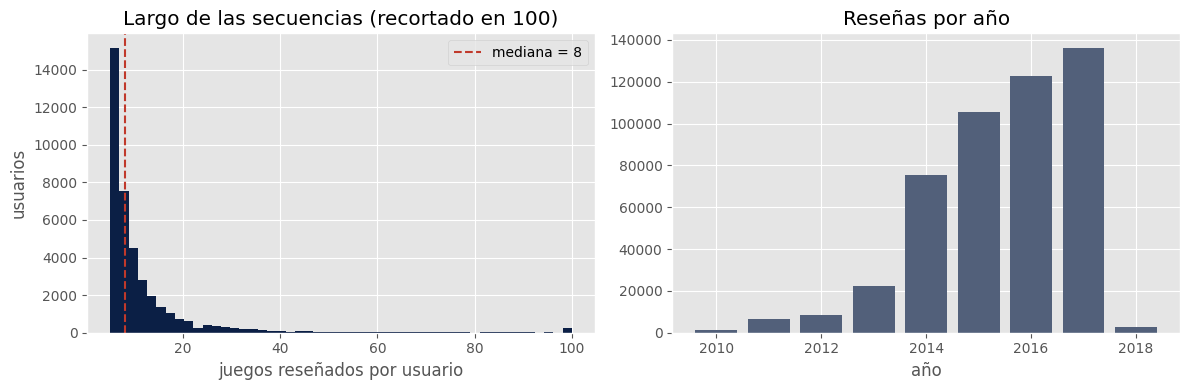

In [17]:
U = len(historial)
densidad = len(datos) / (U * N)
largos = historial.str.len()

print(f"Densidad: {densidad:.4%}  ({len(datos):,} celdas con dato de {U*N:,})")
print(f"Largo de secuencia: media {largos.mean():.1f} | mediana {largos.median():.0f} | "
      f"p90 {largos.quantile(0.9):.0f} | máximo {largos.max()}")
print(f"Usuarios con más de {LARGO} juegos (se recortan a los últimos {LARGO}): {(largos > LARGO).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(largos.clip(upper=100), bins=50, color="#0b1f45")
ax[0].axvline(largos.median(), color="#c0392b", linestyle="--", label=f"mediana = {largos.median():.0f}")
ax[0].set_title("Largo de las secuencias (recortado en 100)")
ax[0].set_xlabel("juegos reseñados por usuario")
ax[0].set_ylabel("usuarios")
ax[0].legend()

por_anio = datos["fecha"].dt.year.value_counts().sort_index()
ax[1].bar(por_anio.index, por_anio.values, color="#52607a")
ax[1].set_title("Reseñas por año")
ax[1].set_xlabel("año")
plt.tight_layout()
plt.show()

El 20% de juegos más populares (1,347) concentra el 78.1% de las reseñas
El juego más popular tiene 4,568 reseñas; la mediana es 18


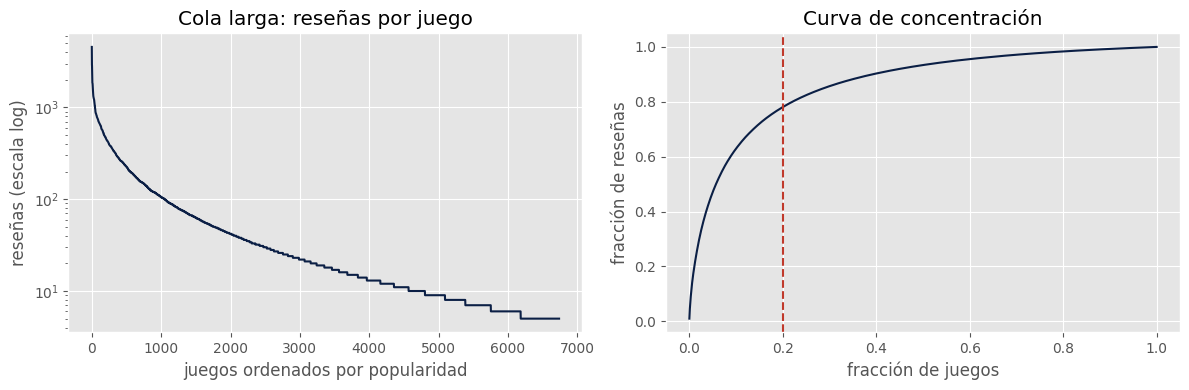

Los 10 juegos más reseñados:


,nombre,genero_principal,precio,popularidad
item,,,,
4896,Team Fortress 2,Action,0.0000,4568
1189,Rust,Adventure,19.9900,3009
3857,Fallout 4,RPG,29.9900,2900
5536,Borderlands 2,Action,19.9900,2855
6293,Portal 2,Adventure,19.9900,2565
4130,Undertale,RPG,9.9900,2053
2570,Life is Strange - Episode 1,Adventure,0.0000,1999
606,DayZ,Massively Multiplayer,34.9900,1993
726,Heroes & Generals,Action,0.0000,1859


In [18]:
# Cola larga: popularidad de cada juego ordenada de mayor a menor
populares = mapa_items["popularidad"].sort_values(ascending=False).values
acumulado = populares.cumsum() / populares.sum()
top20 = int(0.2 * N)

print(f"El 20% de juegos más populares ({top20:,}) concentra el {acumulado[top20-1]:.1%} de las reseñas")
print(f"El juego más popular tiene {populares[0]:,} reseñas; la mediana es {np.median(populares):.0f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(populares, color="#0b1f45")
ax[0].set_yscale("log")
ax[0].set_title("Cola larga: reseñas por juego")
ax[0].set_xlabel("juegos ordenados por popularidad")
ax[0].set_ylabel("reseñas (escala log)")

ax[1].plot(np.arange(1, N + 1) / N, acumulado, color="#0b1f45")
ax[1].axvline(0.2, color="#c0392b", linestyle="--")
ax[1].set_title("Curva de concentración")
ax[1].set_xlabel("fracción de juegos")
ax[1].set_ylabel("fracción de reseñas")
plt.tight_layout()
plt.show()

print("Los 10 juegos más reseñados:")
mapa_items.sort_values("popularidad", ascending=False)[["nombre", "genero_principal", "precio", "popularidad"]].head(10)

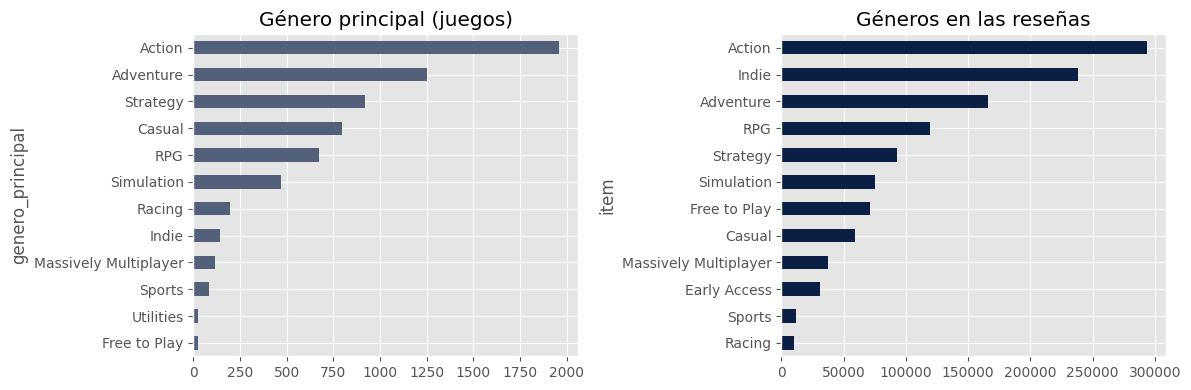

Precio: 10.3% de los juegos son gratis; mediana de los pagados US$ 9.99


In [19]:
# Distribución de géneros: principal (por juego) y todos los géneros (por reseña)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mapa_items["genero_principal"].value_counts().head(12).sort_values().plot.barh(ax=ax[0], color="#52607a")
ax[0].set_title("Género principal (juegos)")

generos_resena = datos["item"].map(mapa_items["generos"]).explode().value_counts().head(12)
generos_resena.sort_values().plot.barh(ax=ax[1], color="#0b1f45")
ax[1].set_title("Géneros en las reseñas")
plt.tight_layout()
plt.show()

print(f"Precio: {mapa_items['precio'].eq(0).mean():.1%} de los juegos son gratis; "
      f"mediana de los pagados US$ {mapa_items.loc[mapa_items['precio'] > 0, 'precio'].median():.2f}")

### 4.1 Evidencia de que el orden importa

Si el orden no importara, dos juegos de un mismo usuario se parecerían igual sin importar cuántos pasos los separan. Medimos el **parecido de género** (índice de Jaccard entre los conjuntos de géneros) entre el juego en la posición $t$ y el juego en la posición $t + d$, para distancias $d = 1, \dots, 10$.

Como control, repetimos la medición con los historiales **barajados al azar** (mismos juegos, orden destruido): si el orden no aportara información, ambas curvas serían iguales.

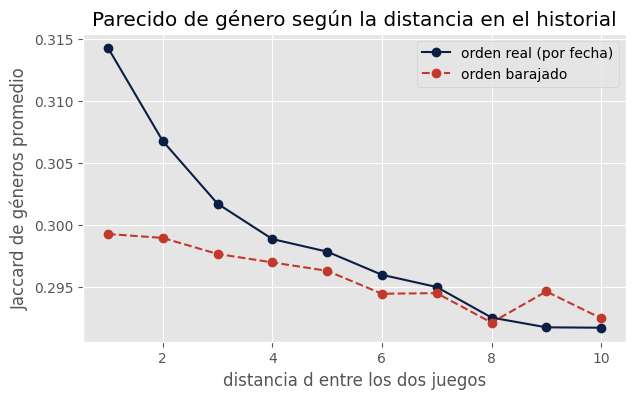

Parecido a distancia 1: real 0.314 vs barajado 0.299 (+5.0%)
Parecido a distancia 10: real 0.292 vs barajado 0.292
Pares consecutivos reseñados el mismo día: 19.2%


In [20]:
conjuntos = mapa_items["generos"].apply(set)


def jaccard(a, b):
    return len(a & b) / len(a | b) if (a or b) else 0.0


def parecido_por_distancia(historiales, distancias):
    resultado = {}
    for d in distancias:
        valores = [jaccard(conjuntos[h[t]], conjuntos[h[t + d]])
                   for h in historiales for t in range(len(h) - d)]
        resultado[d] = np.mean(valores)
    return pd.Series(resultado)


# Muestra de 5.000 usuarios para que sea rápido
rng = np.random.default_rng(SEMILLA)
muestra = [historial.iloc[i] for i in rng.choice(U, size=min(5000, U), replace=False)]
barajados = [list(rng.permutation(h)) for h in muestra]

distancias = range(1, 11)
orden_real = parecido_por_distancia(muestra, distancias)
orden_azar = parecido_por_distancia(barajados, distancias)

# Reseñas del mismo día (empates de fecha)
mismo_dia = datos.groupby("usuario")["fecha"].apply(lambda f: (f.diff().dt.days == 0).sum()).sum() / (len(datos) - U)

plt.figure(figsize=(7, 4))
plt.plot(orden_real.index, orden_real.values, "o-", color="#0b1f45", label="orden real (por fecha)")
plt.plot(orden_azar.index, orden_azar.values, "o--", color="#c0392b", label="orden barajado")
plt.title("Parecido de género según la distancia en el historial")
plt.xlabel("distancia d entre los dos juegos")
plt.ylabel("Jaccard de géneros promedio")
plt.legend()
plt.show()

print(f"Parecido a distancia 1: real {orden_real[1]:.3f} vs barajado {orden_azar[1]:.3f} "
      f"({orden_real[1]/orden_azar[1]-1:+.1%})")
print(f"Parecido a distancia 10: real {orden_real[10]:.3f} vs barajado {orden_azar[10]:.3f}")
print(f"Pares consecutivos reseñados el mismo día: {mismo_dia:.1%}")

### 4.2 Hallazgos

1. **Mucha limpieza necesaria y un 5-core exigente.** De 7,8 millones de reseñas, 903 mil (11,6 %) eran repetidas del mismo usuario al mismo juego. El 5-core deja 3,5 millones de reseñas de 281 mil usuarios y 11.960 juegos: la gran mayoría de los 2,5 millones de usuarios escribió menos de 5 reseñas. Nuestra muestra final tiene **482.019 interacciones, 39.401 usuarios y 6.738 juegos**, muy por sobre los mínimos.
2. **Matriz extremadamente dispersa e historiales cortos.** La densidad es de solo **0,18 %** y la mediana es de **8 juegos** por usuario; solo el 2,3 % supera los 50, así que la ventana `LARGO = 50` cubre casi todos los historiales completos. Con tan pocos datos por persona, comparar usuarios por coincidencias directas es difícil, lo que motiva aprender embeddings.
3. **Cola larga marcada.** El 20 % de los juegos más populares concentra el **78,1 %** de las reseñas: Team Fortress 2 tiene 4.568 reseñas y la mediana es 18. Un recomendador que solo mire popularidad va a acertar seguido pero recomendará siempre lo mismo, por eso medimos cobertura.
4. **El orden importa.** Dos juegos consecutivos se parecen en género un **5,0 % más** que en el orden barajado (Jaccard 0,314 vs 0,299), y el parecido baja hasta igualar al azar a distancia 10. Los gustos recientes dicen más del próximo juego que los antiguos, que es justo lo que aprovecha la atención causal.
5. **Limitación de la fecha.** El **19,2 %** de los pares consecutivos tiene la misma fecha; en esos casos el orden dentro del día viene del archivo original y no del tiempo real. Es ruido en la señal de orden que el modelo debe tolerar.

## 5. Protocolo de evaluación y métricas

**Leave-last-out por usuario**, igual para los cuatro modelos:

| Parte | Qué contiene | Para qué se usa |
|---|---|---|
| Entrenamiento | todos los juegos menos los dos últimos | ajustar los modelos (popularidad, reglas, similitudes y pesos del Transformer) |
| Validación | el penúltimo juego | elegir hiperparámetros y la época de parada |
| Prueba | el último juego | reportar el resultado final **una sola vez** |

Para predecir el ítem de validación, el modelo ve el historial de entrenamiento; para el de prueba, ve entrenamiento + validación.

**Ranking completo:** cada modelo ordena **todo el catálogo**, excluyendo los juegos que el usuario ya reseñó (en Steam no se compra dos veces el mismo juego). No usamos el atajo de comparar contra 100 juegos al azar (como el repositorio SASRec.pytorch), porque infla las métricas.

Si $r_u$ es la posición del juego oculto en la lista del usuario $u$ (1 = primero) y $U$ el número de usuarios:

$$
HR@K = \frac{1}{U}\sum_u \mathbb{1}[r_u \le K], \qquad
NDCG@K = \frac{1}{U}\sum_u \frac{\mathbb{1}[r_u \le K]}{\log_2(r_u + 1)}, \qquad
MRR@K = \frac{1}{U}\sum_u \frac{\mathbb{1}[r_u \le K]}{r_u}
$$

$$
\text{Cobertura@K} = \frac{\left|\bigcup_u \text{Top-}K(u)\right|}{N}
$$

Como hay un solo juego relevante por usuario, el NDCG ideal es 1 y no hace falta normalizar. Si dos juegos empatan en puntaje, todos los modelos desempatan por popularidad.

In [21]:
# Partición leave-last-out
entrena = historial.str[:-2]
valida = historial.str[-2]
prueba = historial.str[-1]
entrena_mas_valida = historial.str[:-1]

usuarios = historial.index.values
print(f"Usuarios: {len(usuarios):,}")
print(f"Interacciones de entrenamiento: {entrena.str.len().sum():,}")
print("Ejemplo usuario 1 → entrenamiento:", entrena.iloc[0], "| validación:", valida.iloc[0], "| prueba:", prueba.iloc[0])

# Popularidad calculada SOLO con entrenamiento (sirve de línea base y de desempate)
conteo = np.zeros(N + 1)
np.add.at(conteo, np.concatenate(entrena.values), 1)
popularidad = torch.tensor(conteo, dtype=torch.float32)
desempate = popularidad / (popularidad.max() + 1) * 1e-3     # < 0,001: solo ordena empates

Usuarios: 39,401
Interacciones de entrenamiento: 403,217
Ejemplo usuario 1 → entrenamiento: [5588, 4635, 646, 5450, 6092, 213, 6475, 12, 6218, 6216] | validación: 861 | prueba: 845


In [22]:
def rellenar(h, largo=LARGO):
    # Últimos `largo` ítems con 0 al inicio (igual que en el notebook del curso)
    h = list(h)[-largo:]
    return [0] * (largo - len(h)) + h


def evaluar(funcion_puntajes, entradas, objetivos, K_lista=K_LISTA, tam=512):
    # Ranking completo del catálogo para cada usuario.
    # funcion_puntajes(lista_de_historiales) -> tensor (B, N+1) con un puntaje por juego
    rangos, tops = [], []
    for ini in range(0, len(entradas), tam):
        lote = list(entradas[ini:ini + tam])
        puntajes = funcion_puntajes(lote).float().to(dispositivo)
        puntajes[:, 0] = -torch.inf                                   # el relleno nunca se recomienda
        vistos = torch.tensor([rellenar(h, max(len(x) for x in lote)) for h in lote], device=dispositivo)
        puntajes.scatter_(1, vistos, -torch.inf)                      # sin juegos ya reseñados
        puntajes[:, 0] = -torch.inf
        obj = torch.tensor(list(objetivos[ini:ini + tam]), device=dispositivo)
        p_obj = puntajes.gather(1, obj[:, None])
        rangos.append(((puntajes > p_obj).sum(1) + 1).cpu())          # posición del juego oculto
        tops.append(puntajes.topk(max(K_lista), dim=1).indices.cpu())
    return torch.cat(rangos).numpy(), torch.cat(tops).numpy()


def metricas(rangos, tops=None, K_lista=K_LISTA):
    fila = {}
    for K in K_lista:
        dentro = rangos <= K
        fila[f"HR@{K}"] = dentro.mean()
        fila[f"NDCG@{K}"] = np.where(dentro, 1 / np.log2(rangos + 1), 0).mean()
        fila[f"MRR@{K}"] = np.where(dentro, 1 / rangos, 0).mean()
    if tops is not None:
        fila["Cobertura@10"] = len(np.unique(tops[:, :10])) / N
    return fila

## 6. Líneas base

Las tres líneas base del curso tratan el historial como una **bolsa de juegos** (excepto el ponderado por recencia de la tercera). Todas se calculan **solo con entrenamiento**.

### 6.1 Popularidad

Recomienda los juegos con más reseñas en entrenamiento que el usuario aún no tiene. Es la misma lista para todos.

In [23]:
def puntajes_popularidad(lote):
    return popularidad.unsqueeze(0).repeat(len(lote), 1)


inicio = time.time()
r_val, t_val = evaluar(puntajes_popularidad, entrena.values, valida.values)
pd.DataFrame([metricas(r_val, t_val)], index=["Popularidad (validación)"])

,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20,Cobertura@10
Popularidad (validación),0.0362,0.0223,0.0179,0.0589,0.0296,0.0208,0.0899,0.0373,0.0229,0.0089


### 6.2 Reglas de asociación (Certamen 2)

Cada historial de entrenamiento es una **canasta**. Igual que en el Certamen 2, minamos con FP-Growth sobre los 300 juegos más populares (con miles de ítems el algoritmo no termina) y nos quedamos con reglas de un juego a otro, $\{A\} \Rightarrow \{B\}$, con lift > 1.

Para recomendar: cada juego del historial activa sus reglas; el puntaje de un candidato es el **mayor lift** entre las reglas que lo recomiendan. Los juegos sin regla activa quedan detrás, ordenados por popularidad (arranque en frío, como en el Certamen 2).

In [24]:
# Canastas: matriz binaria usuario × juego, solo con los TOP_REGLAS más populares en entrenamiento
top_items = np.argsort(-conteo)[:TOP_REGLAS]
top_items = top_items[top_items != 0]
posicion_top = {it: j for j, it in enumerate(top_items)}

canastas = np.zeros((len(entrena), len(top_items)), dtype=bool)
for fila, h in enumerate(entrena.values):
    for it in h:
        if it in posicion_top:
            canastas[fila, posicion_top[it]] = True
canastas = pd.DataFrame(canastas, columns=top_items)
print(f"Canastas: {canastas.shape[0]:,} | juegos: {canastas.shape[1]} | canastas vacías: {(canastas.sum(1)==0).mean():.1%}")

inicio = time.time()
itemsets = fpgrowth(canastas, min_support=0.005, use_colnames=True, max_len=2)
reglas = association_rules(itemsets, metric="lift", min_threshold=1.0)
reglas = reglas[(reglas["antecedents"].apply(len) == 1) & (reglas["confidence"] >= 0.05)].copy()
reglas["A"] = reglas["antecedents"].apply(lambda s: next(iter(s)))
reglas["B"] = reglas["consequents"].apply(lambda s: next(iter(s)))
tiempo_reglas = time.time() - inicio
print(f"Itemsets frecuentes: {len(itemsets):,} | reglas {{A}} ⇒ {{B}} con lift > 1 y confianza ≥ 5%: {len(reglas):,} "
      f"| tiempo: {tiempo_reglas:.1f} s")

tabla = reglas.sort_values("lift", ascending=False).head(8)
pd.DataFrame({"regla": [f"{nombre[a]} ⇒ {nombre[b]}" for a, b in zip(tabla["A"], tabla["B"])],
              "soporte": tabla["support"].values, "confianza": tabla["confidence"].values, "lift": tabla["lift"].values})

Canastas: 39,401 | juegos: 300 | canastas vacías: 7.0%
Itemsets frecuentes: 426 | reglas {A} ⇒ {B} con lift > 1 y confianza ≥ 5%: 252 | tiempo: 16.0 s


,regla,soporte,confianza,lift
0,Saints Row: The Third ⇒ Saints Row IV,0.0064,0.2166,7.5328
1,Saints Row IV ⇒ Saints Row: The Third,0.0064,0.2233,7.5328
2,DayZ ⇒ H1Z1,0.0051,0.1220,5.6557
3,H1Z1 ⇒ DayZ,0.0051,0.2341,5.6557
4,Arma 3 ⇒ DayZ,0.0071,0.2201,5.3173
5,DayZ ⇒ Arma 3,0.0071,0.1704,5.3173
6,H1Z1 ⇒ Rust,0.0070,0.3259,5.2883
7,Rust ⇒ H1Z1,0.0070,0.1141,5.2883


In [25]:
# Matriz de lift: fila = juego antecedente, columna = juego recomendado (0 si no hay regla)
matriz_lift = torch.zeros(N + 1, N + 1)
matriz_lift[torch.tensor(reglas["A"].values), torch.tensor(reglas["B"].values)] = torch.tensor(reglas["lift"].values, dtype=torch.float32)
matriz_lift = matriz_lift.to(dispositivo)


def puntajes_reglas(lote):
    # Mayor lift de las reglas que activa el historial + desempate por popularidad
    entrada = torch.tensor([rellenar(h) for h in lote], device=dispositivo)
    lift_max = matriz_lift[entrada].max(dim=1).values          # (B, N+1)
    return lift_max + desempate.to(dispositivo)


r_val, t_val = evaluar(puntajes_reglas, entrena.values, valida.values, tam=128)
pd.DataFrame([metricas(r_val, t_val)], index=["Reglas (validación)"])

,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20,Cobertura@10
Reglas (validación),0.0367,0.0225,0.0179,0.0619,0.0306,0.0212,0.0945,0.0387,0.0234,0.0093


### 6.3 Ítem–ítem con coseno, ponderando los últimos juegos

La similitud entre dos juegos es el **coseno** entre sus columnas de la matriz binaria usuario × juego (entrenamiento):

$$
sim(i, j) = \frac{|U_i \cap U_j|}{\sqrt{|U_i|\,|U_j|}}
$$

El puntaje de un candidato $j$ suma su similitud con los juegos del historial, dando más peso a los recientes: el último juego pesa 1, el penúltimo $\gamma$, el anterior $\gamma^2$, etc. El **decaimiento** $\gamma$ se elige con validación: $\gamma = 1$ es la bolsa de juegos clásica.

In [26]:
inicio = time.time()
filas = np.repeat(np.arange(len(entrena)), entrena.str.len().values)
columnas = np.concatenate(entrena.values)
X = sparse.csr_matrix((np.ones(len(columnas), dtype=np.float32), (filas, columnas)), shape=(len(entrena), N + 1))

coocurrencia = (X.T @ X).toarray().astype(np.float32)
norma = np.sqrt(np.diag(coocurrencia))
similitud = (coocurrencia / (np.outer(norma, norma) + 1e-9)).astype(np.float32)
np.fill_diagonal(similitud, 0)
similitud = torch.tensor(similitud, dtype=torch.float32, device=dispositivo)
del coocurrencia
tiempo_coseno = time.time() - inicio
print(f"Matriz de similitud: {tuple(similitud.shape)} | tiempo: {tiempo_coseno:.1f} s")


def crear_puntajes_coseno(gamma):
    pesos_posicion = torch.tensor([gamma ** (LARGO - 1 - p) for p in range(LARGO)], dtype=torch.float32, device=dispositivo)
    def puntajes(lote):
        entrada = torch.tensor([rellenar(h) for h in lote], device=dispositivo)
        pesos = pesos_posicion.unsqueeze(0) * (entrada != 0)                 # (B, LARGO)
        return torch.einsum("bl,bln->bn", pesos, similitud[entrada]) + desempate.to(dispositivo)
    return puntajes


# Elegir el decaimiento con validación
busqueda = []
for gamma in [1.0, 0.9, 0.7, 0.5, 0.3]:
    r_val, _ = evaluar(crear_puntajes_coseno(gamma), entrena.values, valida.values, tam=128)
    busqueda.append({"gamma": gamma, **metricas(r_val)})
busqueda = pd.DataFrame(busqueda).set_index("gamma")
GAMMA = float(busqueda["NDCG@10"].idxmax())
print(f"Decaimiento elegido con validación: gamma = {GAMMA}")
busqueda[["HR@10", "NDCG@10", "MRR@20"]]

Matriz de similitud: (6739, 6739) | tiempo: 1.0 s
Decaimiento elegido con validación: gamma = 0.9


,HR@10,NDCG@10,MRR@20
gamma,,,
1.0000,0.0870,0.0444,0.0348
0.9000,0.0902,0.0465,0.0366
0.7000,0.0884,0.0464,0.0368
0.5000,0.0810,0.0428,0.0341
0.3000,0.0710,0.0377,0.0302


## 7. Transformer: SASRec

SASRec (Kang y McAuley, 2018) lee el historial como una **oración**: cada juego es una palabra y el modelo, igual que GPT, aprende a predecir la **siguiente** en cada posición. Seguimos el algoritmo del handout de la clase y la arquitectura del repositorio [SASRec.pytorch](https://github.com/pmixer/SASRec.pytorch), escrita de nuevo y explicada bloque a bloque:

| Bloque | Qué hace | En el código |
|---|---|---|
| **1. Embedding de ítem** | Cada juego es un vector de tamaño $d$ que se aprende. El 0 (relleno) es un vector nulo. | `nn.Embedding(N+1, d, padding_idx=0)` |
| **2. Embedding de posición** | Se suma un vector por posición en la ventana: así el modelo sabe qué juego es más reciente. Sin esto, la atención sería una bolsa de juegos. | `nn.Embedding(LARGO, d)` |
| **3. Atención causal** | Cada posición calcula consulta, clave y valor ($Q, K, V$) y mira a las demás con $\text{softmax}(QK^T/\sqrt{d})V$. La **máscara triangular** suma $-\infty$ a las posiciones futuras, para que al predecir el juego $t+1$ solo se use el pasado. También se ocultan las posiciones de relleno. | `torch.triu(...)` + `nn.MultiheadAttention` |
| **4. Residual y normalización** | Se suma la entrada a la salida de la atención (residual), para que la información original no se pierda, y se normaliza (`LayerNorm`) antes de cada subcapa para estabilizar el entrenamiento. | `x = x + atencion(norma(x))` |
| **5. Feed-forward** | Dos capas lineales con ReLU aplicadas a cada posición por separado: procesan lo que la atención reunió. | `nn.Sequential(Linear, ReLU, Dropout, Linear)` |
| **6. Salida** | El vector de la posición $t$, $h_t$, resume al usuario hasta ese momento. El puntaje de cada juego es $r_{t,i} = h_t \cdot E[i]$, **reutilizando** la misma tabla de embeddings de la entrada. | `h @ self.items.weight.T` |

Los bloques 3 a 5 forman un **bloque Transformer**, que se apila 1 o 2 veces.

**Pérdida: entropía cruzada sobre todo el catálogo.** En cada posición, el softmax de los puntajes compite entre los $N$ juegos y la pérdida es $-\log P(\text{juego siguiente real})$. La justificación:

1. Es la pérdida del handout de la clase y la misma de un modelo de lenguaje como GPT.
2. Coincide con cómo evaluamos: el modelo aprende a poner el juego correcto **arriba de todo el catálogo**, que es lo que mide el ranking completo.
3. Con unos miles de juegos, calcular el softmax completo en la GPU es barato. El repositorio original usa BCE con **un solo** negativo al azar, que es más rápido en catálogos enormes, pero solo aprende a ganarle a ese juego y obliga a muestrear negativos. Con entropía cruzada completa no hay negativos que muestrear.

Las posiciones de relleno se ignoran en la pérdida (`ignore_index=0`).

In [27]:
# Ejemplos de entrenamiento como en el notebook del curso:
# con los juegos 1-50 aprende a predecir los juegos 2-51 (trozos de 51 que avanzan de a 25)
entradas, respuestas = [], []
for h in entrena:
    for i in range(0, len(h) - 1, PASO):
        trozo = h[i:i + LARGO + 1]
        entradas.append(rellenar(trozo[:-1]))
        respuestas.append(rellenar(trozo[1:]))
X_tr, Y_tr = torch.tensor(entradas), torch.tensor(respuestas)
print(f"Ejemplos: {len(X_tr):,} | posiciones con juego a predecir: {(Y_tr != 0).sum().item():,}")
print("Ejemplo (últimas 8 posiciones):")
print("  entrada  :", X_tr[0, -8:].tolist())
print("  respuesta:", Y_tr[0, -8:].tolist())

Ejemplos: 43,983 | posiciones con juego a predecir: 440,843
Ejemplo (últimas 8 posiciones):
  entrada  : [4635, 646, 5450, 6092, 213, 6475, 12, 6218]
  respuesta: [646, 5450, 6092, 213, 6475, 12, 6218, 6216]


In [28]:
class BloqueTransformer(nn.Module):
    # Atención causal + feed-forward, cada una con normalización previa y conexión residual
    def __init__(self, d, cabezas, dropout):
        super().__init__()
        self.norma_atencion = nn.LayerNorm(d)
        self.atencion = nn.MultiheadAttention(d, cabezas, dropout=dropout, batch_first=True)
        self.norma_ffn = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d, d))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mascara, guardar_pesos=False):
        h = self.norma_atencion(x)
        salida, pesos = self.atencion(h, h, h, attn_mask=mascara,
                                      need_weights=guardar_pesos, average_attn_weights=True)
        x = x + self.dropout(salida)                              # residual 1
        x = x + self.dropout(self.ffn(self.norma_ffn(x)))         # residual 2
        return x, pesos


class SASRec(nn.Module):
    def __init__(self, n_items, largo=LARGO, d=64, bloques=2, cabezas=1, dropout=0.2):
        super().__init__()
        self.d, self.cabezas = d, cabezas
        self.items = nn.Embedding(n_items + 1, d, padding_idx=0)   # bloque 1
        self.posiciones = nn.Embedding(largo, d)                   # bloque 2
        self.dropout = nn.Dropout(dropout)
        self.bloques = nn.ModuleList([BloqueTransformer(d, cabezas, dropout) for _ in range(bloques)])
        self.norma_final = nn.LayerNorm(d)
        nn.init.normal_(self.items.weight, std=0.05)
        nn.init.normal_(self.posiciones.weight, std=0.05)
        with torch.no_grad():
            self.items.weight[0].zero_()
        self.pesos_atencion = None

    def codificar(self, seq, guardar_pesos=False):
        B, L = seq.shape
        pos = torch.arange(L, device=seq.device).unsqueeze(0)
        es_item = (seq != 0).unsqueeze(-1)
        x = self.items(seq) * self.d ** 0.5 + self.posiciones(pos)
        x = self.dropout(x) * es_item

        # Máscara (True = no puede mirar): futuro (triangular superior) + columnas de relleno.
        # La diagonal siempre queda permitida, para que las filas de relleno no queden vacías.
        futuro = torch.triu(torch.ones(L, L, dtype=torch.bool, device=seq.device), diagonal=1)
        relleno = (seq == 0).unsqueeze(1)
        diagonal = torch.eye(L, dtype=torch.bool, device=seq.device)
        mascara = (futuro.unsqueeze(0) | relleno) & ~diagonal
        mascara = mascara.repeat_interleave(self.cabezas, dim=0)       # una por cabeza

        for bloque in self.bloques:
            x, pesos = bloque(x, mascara, guardar_pesos)
            x = x * es_item
        self.pesos_atencion = pesos                                   # pesos del último bloque
        return self.norma_final(x)

    def forward(self, seq):
        # Entrenamiento: puntajes de todo el catálogo en cada posición (B, L, N+1)
        return self.codificar(seq) @ self.items.weight.T

    def puntajes(self, seq, guardar_pesos=False):
        # Inferencia: solo el vector de la última posición (B, N+1)
        return self.codificar(seq, guardar_pesos)[:, -1, :] @ self.items.weight.T


# Prueba de la máscara con una secuencia de 5 posiciones, 2 de relleno
modelo_prueba = SASRec(N, largo=5, d=8, bloques=1, cabezas=1).eval()
with torch.no_grad():
    modelo_prueba.puntajes(torch.tensor([[0, 0, 3, 7, 2]]), guardar_pesos=True)
print("Pesos de atención (filas = posición que mira, columnas = posición mirada):")
print(modelo_prueba.pesos_atencion[0].numpy().round(2))

Pesos de atención (filas = posición que mira, columnas = posición mirada):
[[1.   0.   0.   0.   0.  ]
 [0.   1.   0.   0.   0.  ]
 [0.   0.   1.   0.   0.  ]
 [0.   0.   0.37 0.63 0.  ]
 [0.   0.   0.33 0.25 0.42]]


En la matriz de prueba se ve la máscara funcionando: **todo lo que está sobre la diagonal es 0** (nadie mira el futuro), las columnas de relleno también son 0 para las filas reales, y cada fila suma 1 por el softmax.

### 7.1 Entrenamiento con validación y parada temprana

Para cada configuración:

1. Se entrena por épocas con Adam (tasa 0,001) sobre los trozos de entrenamiento.
2. Al final de cada época se mide **NDCG@10 en validación** (ranking completo).
3. Se guarda el mejor estado y se detiene si pasan 5 épocas sin mejorar (**parada temprana**).

La prueba **no se mira** en esta etapa.

In [29]:
def entrenar(config, nombre_config):
    torch.manual_seed(SEMILLA)
    modelo = SASRec(N, LARGO, **config).to(dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    funcion_perdida = nn.CrossEntropyLoss(ignore_index=0)
    cargador = DataLoader(TensorDataset(X_tr, Y_tr), batch_size=TAM_LOTE, shuffle=True,
                          generator=torch.Generator().manual_seed(SEMILLA))

    def puntajes_val(lote):
        with torch.no_grad():
            return modelo.puntajes(torch.tensor([rellenar(h) for h in lote], device=dispositivo))

    curvas, mejor, mejor_estado, sin_mejora = [], -1, None, 0
    inicio = time.time()
    for epoca in range(1, EPOCAS_MAX + 1):
        modelo.train()
        total, n = 0.0, 0
        for xb, yb in cargador:
            xb, yb = xb.to(dispositivo), yb.to(dispositivo)
            logits = modelo(xb)
            perdida = funcion_perdida(logits.reshape(-1, N + 1), yb.reshape(-1))
            optimizador.zero_grad()
            perdida.backward()
            optimizador.step()
            total += perdida.item() * len(xb); n += len(xb)

        modelo.eval()
        r_val, _ = evaluar(puntajes_val, entrena.values, valida.values)
        m = metricas(r_val)
        curvas.append({"config": nombre_config, "epoca": epoca, "perdida": total / n,
                       "HR@10_val": m["HR@10"], "NDCG@10_val": m["NDCG@10"]})
        print(f"  época {epoca:2d} | pérdida {total/n:.4f} | val HR@10 {m['HR@10']:.4f} | val NDCG@10 {m['NDCG@10']:.4f}")

        if m["NDCG@10"] > mejor:
            mejor, mejor_epoca, sin_mejora = m["NDCG@10"], epoca, 0
            mejor_estado = copy.deepcopy(modelo.state_dict())
        else:
            sin_mejora += 1
            if sin_mejora >= PACIENCIA:
                print(f"  Parada temprana: {PACIENCIA} épocas sin mejorar")
                break

    modelo.load_state_dict(mejor_estado)
    resumen = {"config": nombre_config, **config, "mejor_epoca": mejor_epoca, "NDCG@10_val": mejor,
               "parametros": sum(p.numel() for p in modelo.parameters()),
               "tiempo_s": time.time() - inicio}
    return modelo, pd.DataFrame(curvas), resumen

**Tres configuraciones**, de menor a mayor capacidad:

| Config. | $d$ | Bloques | Cabezas | Dropout | Idea |
|---|---|---|---|---|---|
| A | 64 | 1 | 1 | 0,2 | Modelo mínimo |
| B | 64 | 2 | 2 | 0,2 | Más profundidad y dos cabezas (cada una puede seguir un patrón distinto) |
| C | 128 | 2 | 2 | 0,3 | Vectores más grandes, con más dropout para no sobreajustar |

In [30]:
CONFIGS = {
    "A": dict(d=64, bloques=1, cabezas=1, dropout=0.2),
    "B": dict(d=64, bloques=2, cabezas=2, dropout=0.2),
    "C": dict(d=128, bloques=2, cabezas=2, dropout=0.3),
}

modelos, curvas, resumenes = {}, [], []
for nombre_config, config in CONFIGS.items():
    print(f"\nConfiguración {nombre_config}: {config}")
    modelos[nombre_config], c, r = entrenar(config, nombre_config)
    curvas.append(c); resumenes.append(r)

curvas = pd.concat(curvas)
resumen_configs = pd.DataFrame(resumenes).set_index("config")
MEJOR = resumen_configs["NDCG@10_val"].idxmax()
sasrec = modelos[MEJOR]
print(f"\nConfiguración elegida con validación: {MEJOR}")
resumen_configs


Configuración A: {'d': 64, 'bloques': 1, 'cabezas': 1, 'dropout': 0.2}
  época  1 | pérdida 7.9280 | val HR@10 0.0609 | val NDCG@10 0.0307
  época  2 | pérdida 7.6046 | val HR@10 0.0778 | val NDCG@10 0.0395
  época  3 | pérdida 7.3990 | val HR@10 0.0870 | val NDCG@10 0.0452
  época  4 | pérdida 7.2699 | val HR@10 0.0936 | val NDCG@10 0.0484
  época  5 | pérdida 7.1770 | val HR@10 0.0979 | val NDCG@10 0.0510
  época  6 | pérdida 7.1083 | val HR@10 0.1002 | val NDCG@10 0.0521
  época  7 | pérdida 7.0510 | val HR@10 0.1015 | val NDCG@10 0.0527
  época  8 | pérdida 7.0063 | val HR@10 0.1017 | val NDCG@10 0.0533
  época  9 | pérdida 6.9654 | val HR@10 0.1024 | val NDCG@10 0.0541
  época 10 | pérdida 6.9343 | val HR@10 0.1024 | val NDCG@10 0.0549
  época 11 | pérdida 6.9073 | val HR@10 0.1041 | val NDCG@10 0.0551
  época 12 | pérdida 6.8850 | val HR@10 0.1044 | val NDCG@10 0.0553
  época 13 | pérdida 6.8680 | val HR@10 0.1052 | val NDCG@10 0.0554
  época 14 | pérdida 6.8512 | val HR@10 0.10

,d,bloques,cabezas,dropout,mejor_epoca,NDCG@10_val,parametros,tiempo_s
config,,,,,,,,
A,64,1,1,0.2000,26,0.0580,459840,257.9175
B,64,2,2,0.2000,17,0.0594,485056,205.6865
C,128,2,2,0.3000,18,0.0609,1068416,280.4601


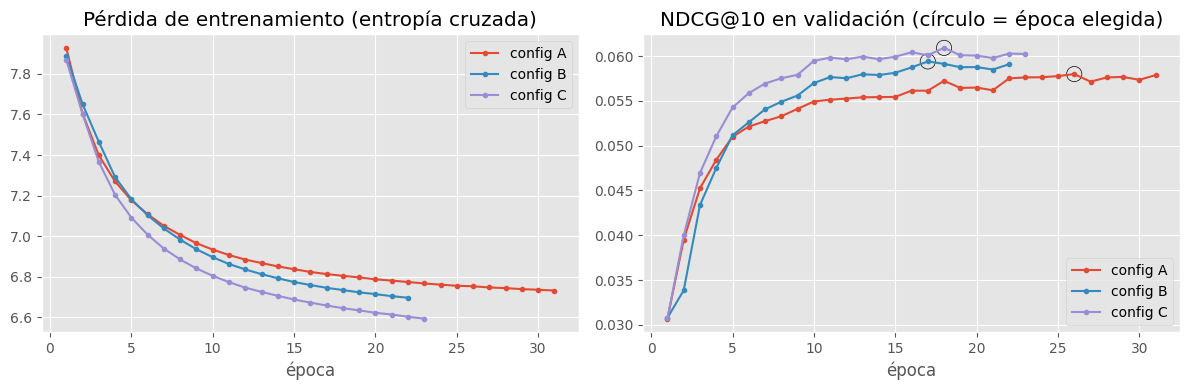

In [31]:
# Curvas por época
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nombre_config, c in curvas.groupby("config"):
    ax[0].plot(c["epoca"], c["perdida"], "o-", markersize=3, label=f"config {nombre_config}")
    ax[1].plot(c["epoca"], c["NDCG@10_val"], "o-", markersize=3, label=f"config {nombre_config}")
    mejor_fila = c.loc[c["NDCG@10_val"].idxmax()]
    ax[1].scatter(mejor_fila["epoca"], mejor_fila["NDCG@10_val"], s=120, facecolors="none", edgecolors="black")
ax[0].set_title("Pérdida de entrenamiento (entropía cruzada)")
ax[0].set_xlabel("época")
ax[1].set_title("NDCG@10 en validación (círculo = época elegida)")
ax[1].set_xlabel("época")
ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.show()

## 8. Comparación final

### 8.1 Prueba: se reporta una sola vez

Con los hiperparámetros ya fijados en validación (configuración de SASRec y decaimiento $\gamma$ del coseno), cada modelo predice el **último juego** de cada usuario viendo entrenamiento + validación.

In [32]:
def puntajes_sasrec(lote, modelo=None):
    modelo = modelo or sasrec
    modelo.eval()
    with torch.no_grad():
        return modelo.puntajes(torch.tensor([rellenar(h) for h in lote], device=dispositivo))


MODELOS = {
    "Popularidad": puntajes_popularidad,
    "Reglas de asociación": puntajes_reglas,
    f"Ítem–ítem coseno (γ={GAMMA})": crear_puntajes_coseno(GAMMA),
    f"SASRec (config {MEJOR})": puntajes_sasrec,
}

resultados, rangos_prueba, tops_prueba, tiempo_inferencia = {}, {}, {}, {}
for nombre_modelo, funcion in MODELOS.items():
    inicio = time.time()
    rangos_prueba[nombre_modelo], tops_prueba[nombre_modelo] = evaluar(funcion, entrena_mas_valida.values, prueba.values, tam=128)
    tiempo_inferencia[nombre_modelo] = (time.time() - inicio) / len(usuarios) * 1000
    resultados[nombre_modelo] = metricas(rangos_prueba[nombre_modelo], tops_prueba[nombre_modelo])

tabla_final = pd.DataFrame(resultados).T
columnas = [f"{m}@{K}" for K in K_LISTA for m in ["HR", "NDCG", "MRR"]] + ["Cobertura@10"]
tabla_final = tabla_final[columnas]
tabla_final.style.format("{:.4f}").highlight_max(axis=0, color="#c8e6c9")

,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20,Cobertura@10
Popularidad,0.0363,0.0221,0.0175,0.0552,0.0282,0.0200,0.0827,0.0350,0.0218,0.0089
Reglas de asociación,0.0367,0.0223,0.0176,0.0572,0.0288,0.0203,0.0865,0.0362,0.0222,0.0093
Ítem–ítem coseno (γ=0.9),0.0526,0.0345,0.0285,0.0861,0.0452,0.0329,0.1330,0.0570,0.0361,0.7563
SASRec (config C),0.0690,0.0446,0.0366,0.1110,0.0580,0.0421,0.1698,0.0728,0.0461,0.5646


Mejora relativa de SASRec sobre la mejor línea base:
HR@10           +29.0%
NDCG@10         +28.4%
MRR@20          +27.6%
Cobertura@10    -25.4%


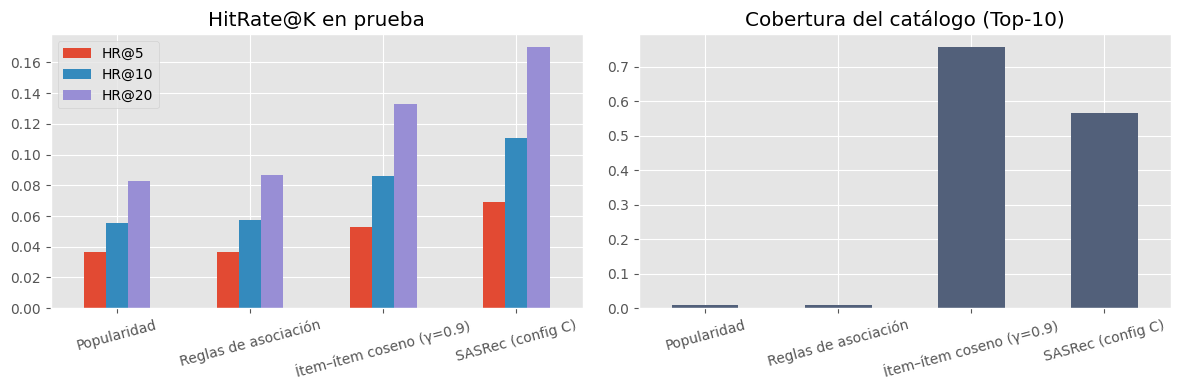

In [33]:
# Mejora relativa de SASRec sobre la mejor línea base en cada métrica
nombre_sasrec = f"SASRec (config {MEJOR})"
mejor_base = tabla_final.drop(nombre_sasrec).max()
mejora = (tabla_final.loc[nombre_sasrec] / mejor_base - 1)
print("Mejora relativa de SASRec sobre la mejor línea base:")
print(mejora[["HR@10", "NDCG@10", "MRR@20", "Cobertura@10"]].map(lambda v: f"{v:+.1%}").to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tabla_final[["HR@5", "HR@10", "HR@20"]].plot.bar(ax=ax[0], rot=15)
ax[0].set_title("HitRate@K en prueba")
tabla_final[["Cobertura@10"]].plot.bar(ax=ax[1], rot=15, color="#52607a", legend=False)
ax[1].set_title("Cobertura del catálogo (Top-10)")
plt.tight_layout()
plt.show()

### 8.2 Verificación a mano de las métricas en un usuario

Tomamos un usuario de prueba, buscamos en qué posición quedó su juego oculto en la lista de SASRec y calculamos las métricas con las fórmulas.

In [34]:
# Primer usuario cuyo juego oculto quedó entre los 10 primeros de SASRec
r = rangos_prueba[nombre_sasrec]
u = int(np.where((r > 1) & (r <= 10))[0][0])
h = entrena_mas_valida.values[u]
oculto = prueba.values[u]

with torch.no_grad():
    p = puntajes_sasrec([h])[0].cpu()
p[0] = -torch.inf
p[torch.tensor(h)] = -torch.inf
orden = torch.argsort(p, descending=True)[:10].tolist()

print(f"Usuario {usuarios[u]} | últimos 5 juegos del historial:")
for it in h[-5:]:
    print(f"   {nombre[it]} ({genero[it]})")
print(f"Juego oculto (prueba): {nombre[oculto]} ({genero[oculto]})\n")
print("Top-10 de SASRec:")
for pos, it in enumerate(orden, 1):
    print(f"  {pos:2d}. {nombre[it]} ({genero[it]})" + ("   <-- juego oculto" if it == oculto else ""))

rango = orden.index(oculto) + 1
print(f"\nPosición del juego oculto: r = {rango}")
for K in K_LISTA:
    hr = 1 if rango <= K else 0
    ndcg = 1 / np.log2(rango + 1) if rango <= K else 0
    mrr = 1 / rango if rango <= K else 0
    print(f"  K={K:2d}: HR = {hr} | NDCG = 1/log2({rango}+1) = {ndcg:.4f} | MRR = 1/{rango} = {mrr:.4f}")

print("\nMétricas de la función `metricas` para el mismo usuario:")
pd.DataFrame([metricas(np.array([r[u]]))]).round(4)

Usuario 29 | últimos 5 juegos del historial:
   Alien Swarm (Action)
   FOTONICA (Action)
   Geometry Wars™ 3: Dimensions Evolved (Action)
   Devil Daggers (Action)
Juego oculto (prueba): SUPERHOT (Action)

Top-10 de SASRec:
   1. THOTH (Action)
   2. SUPERHOT (Action)   <-- juego oculto
   3. Warframe (Action)
   4. NECROPOLIS: BRUTAL EDITION (Adventure)
   5. Factorio (Strategy)
   6. Shadow Warrior 2 (Action)
   7. N++ (NPLUSPLUS) (Action)
   8. Blood and Bacon (Action)
   9. Slain: Back from Hell (Action)
  10. Undertale (RPG)

Posición del juego oculto: r = 2
  K= 5: HR = 1 | NDCG = 1/log2(2+1) = 0.6309 | MRR = 1/2 = 0.5000
  K=10: HR = 1 | NDCG = 1/log2(2+1) = 0.6309 | MRR = 1/2 = 0.5000
  K=20: HR = 1 | NDCG = 1/log2(2+1) = 0.6309 | MRR = 1/2 = 0.5000

Métricas de la función `metricas` para el mismo usuario:


,HR@5,NDCG@5,MRR@5,HR@10,NDCG@10,MRR@10,HR@20,NDCG@20,MRR@20
0,1.0000,0.6309,0.5000,1.0000,0.6309,0.5000,1.0000,0.6309,0.5000


### 8.3 Costo: tiempo, parámetros e inferencia

In [35]:
costo = pd.DataFrame({
    "parámetros / tamaño": {
        "Popularidad": f"{N:,} conteos",
        "Reglas de asociación": f"{len(reglas):,} reglas",
        f"Ítem–ítem coseno (γ={GAMMA})": f"{(N+1)**2:,} similitudes",
        nombre_sasrec: f"{resumen_configs.loc[MEJOR, 'parametros']:,} pesos",
    },
    "entrenamiento (s)": {
        "Popularidad": 0.0,
        "Reglas de asociación": tiempo_reglas,
        f"Ítem–ítem coseno (γ={GAMMA})": tiempo_coseno,
        nombre_sasrec: resumen_configs.loc[MEJOR, "tiempo_s"],
    },
    "inferencia (ms por usuario)": tiempo_inferencia,
})
costo["NDCG@10"] = tabla_final["NDCG@10"]
print(f"Dispositivo: {dispositivo}. Entrenamiento total de las 3 configuraciones: {resumen_configs['tiempo_s'].sum():.0f} s")
costo

Dispositivo: cuda. Entrenamiento total de las 3 configuraciones: 744 s


,parámetros / tamaño,entrenamiento (s),inferencia (ms por usuario),NDCG@10
Popularidad,"6,738 conteos",0.0000,0.0468,0.0282
Reglas de asociación,252 reglas,15.9803,0.0705,0.0288
Ítem–ítem coseno (γ=0.9),"45,414,121 similitudes",1.0368,0.0675,0.0452
SASRec (config C),"1,068,416 pesos",280.4601,0.0904,0.0580


### 8.4 Segmentos: historial corto/largo y juego popular/cola larga

- **Historial:** corto si el usuario tiene a lo más la mediana de juegos en entrenamiento; largo si tiene más.
- **Juego oculto:** popular si está en el 20 % de juegos más reseñados en entrenamiento; cola larga si no.

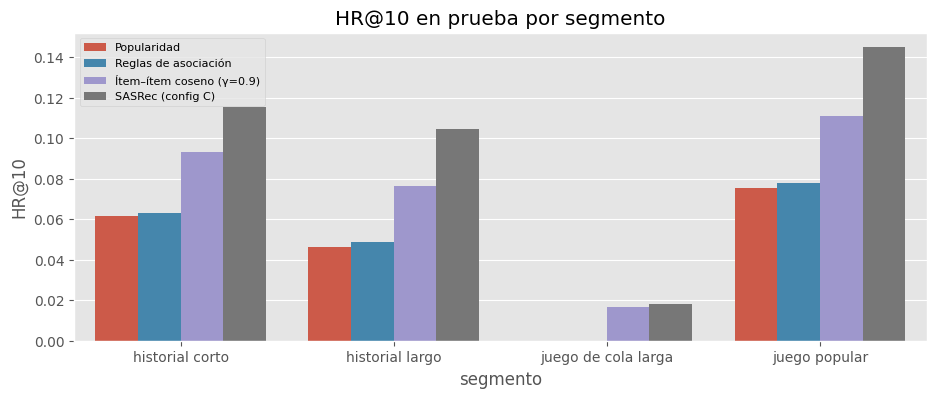

modelo,Popularidad,Reglas de asociación,SASRec (config C),Ítem–ítem coseno (γ=0.9)
segmento,,,,
historial corto,0.0617,0.0633,0.1156,0.0933
historial largo,0.0463,0.0489,0.1047,0.0762
juego de cola larga,0.0000,0.0000,0.0179,0.0168
juego popular,0.0753,0.0780,0.1449,0.1112


In [36]:
largo_hist = entrena_mas_valida.str.len().values
segmento_hist = np.where(largo_hist <= np.median(largo_hist), "historial corto", "historial largo")
cabeza = set(np.argsort(-conteo)[:int(0.2 * N)])
segmento_item = np.where([it in cabeza for it in prueba.values], "juego popular", "juego de cola larga")

filas = []
for nombre_modelo, r in rangos_prueba.items():
    for etiqueta, segmento in [("historial", segmento_hist), ("juego", segmento_item)]:
        for valor in np.unique(segmento):
            m = metricas(r[segmento == valor])
            filas.append({"modelo": nombre_modelo, "segmento": valor, "usuarios": (segmento == valor).sum(),
                          "HR@10": m["HR@10"], "NDCG@10": m["NDCG@10"]})
segmentos = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(data=segmentos, x="segmento", y="HR@10", hue="modelo", ax=ax)
ax.set_title("HR@10 en prueba por segmento")
plt.legend(fontsize=8)
plt.show()
segmentos.pivot(index="segmento", columns="modelo", values="HR@10")

### 8.5 Tres usuarios: historial, recomendación y pesos de atención

Elegimos tres usuarios con historiales de distinto largo. Para cada uno se muestra su historial, el Top-5 de SASRec y los **pesos de atención** de la última posición (la que genera la recomendación): indican en qué juegos del historial se fijó el modelo.


=== Usuario de historial corto (5 juegos) ===
Últimos juegos: Robocraft → PlanetSide 2 → ARK: Survival Of The Fittest → Deepworld → Oxygen Not Included
Top-5 SASRec:  Grand Theft Auto V (Action) | Warframe (Action) | ARK: Survival Evolved (Adventure) | Tom Clancy's Rainbow Six® Siege (Action) | Black Squad (Action)
Juego real siguiente: TERA (Massively Multiplayer)

=== Usuario de historial medio (13 juegos) ===
Últimos juegos: Brothers - A Tale of Two Sons → Awkward Dimensions Redux → Burnout Paradise: The Ultimate Box → Thomas Was Alone → Never Alone (Kisima Ingitchuna) → Shadowrun: Dragonfall - Director's Cut
Top-5 SASRec:  Life is Strange - Episode 1 (Adventure) | Borderlands 2 (Action) | Refunct (Casual) | Fallout 4 (RPG) | Metro 2033 Redux (Action)
Juego real siguiente: Soda Dungeon (RPG)

=== Usuario de historial largo (42 juegos) ===
Últimos juegos: Risen 2: Dark Waters → Tom Clancy's Rainbow Six® Siege → Epic Tavern → TEKKEN 7 → Squad → Insurgency
Top-5 SASRec:  Counter-Strik

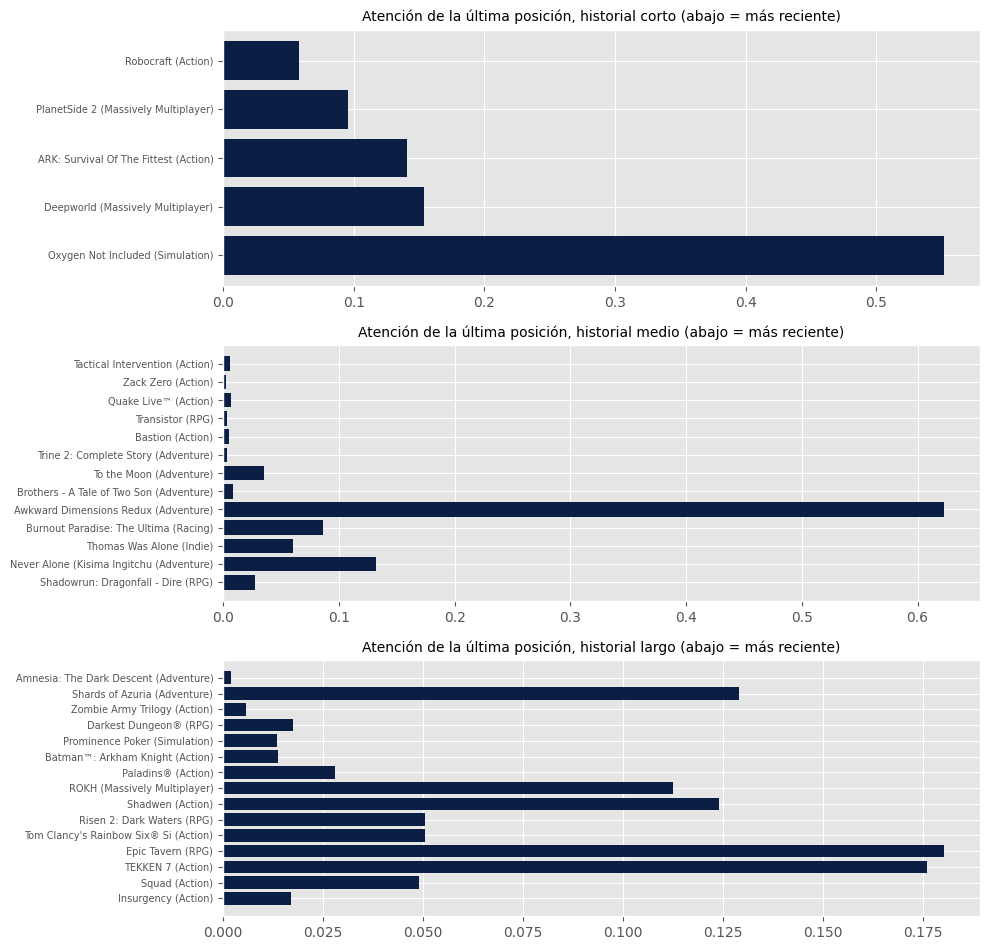

In [37]:
rng = np.random.default_rng(SEMILLA)
largos_u = entrena_mas_valida.str.len().values
grupos = [("corto", (largos_u >= 4) & (largos_u <= 6)), ("medio", (largos_u >= 10) & (largos_u <= 15)),
          ("largo", (largos_u >= 25) & (largos_u <= LARGO))]
elegidos_u = [(etiqueta, int(rng.choice(np.where(cond)[0]))) for etiqueta, cond in grupos if cond.any()]

fig, ejes = plt.subplots(len(elegidos_u), 1, figsize=(10, 3.2 * len(elegidos_u)))
for eje, (etiqueta, u) in zip(np.atleast_1d(ejes), elegidos_u):
    h = list(entrena_mas_valida.values[u])
    entrada = torch.tensor([rellenar(h)], device=dispositivo)
    sasrec.eval()
    with torch.no_grad():
        p = sasrec.puntajes(entrada, guardar_pesos=True)[0].cpu()
    p[0] = -torch.inf; p[torch.tensor(h)] = -torch.inf
    top5 = torch.argsort(p, descending=True)[:5].tolist()

    # Pesos de la última posición sobre los juegos reales (los últimos 15 para que se lean)
    pesos = sasrec.pesos_atencion[0, -1].cpu().numpy()[-min(len(h), LARGO):]
    mostrar = min(15, len(pesos))
    etiquetas = [f"{nombre[it][:28]} ({genero[it]})" for it in h[-mostrar:]]

    print(f"\n=== Usuario de historial {etiqueta} ({len(h)} juegos) ===")
    print("Últimos juegos:", " → ".join(nombre[it] for it in h[-6:]))
    print("Top-5 SASRec: ", " | ".join(f"{nombre[it]} ({genero[it]})" for it in top5))
    print("Juego real siguiente:", nombre[prueba.values[u]], f"({genero[prueba.values[u]]})")

    eje.barh(range(mostrar), pesos[-mostrar:], color="#0b1f45")
    eje.set_yticks(range(mostrar), etiquetas, fontsize=7)
    eje.set_title(f"Atención de la última posición, historial {etiqueta} (abajo = más reciente)", fontsize=10)
    eje.invert_yaxis()
plt.tight_layout()
plt.show()

### 8.6 Embeddings de los juegos por género

Proyectamos los embeddings $E$ aprendidos por SASRec a 2 dimensiones con **ACP** (unidad 1 del curso) y los coloreamos por género principal. Si el modelo aprendió algo del tipo de juego sin que se lo dijéramos (SASRec nunca vio los géneros), los juegos del mismo género deberían quedar cerca. Lo medimos también con la similitud coseno promedio dentro y entre géneros.

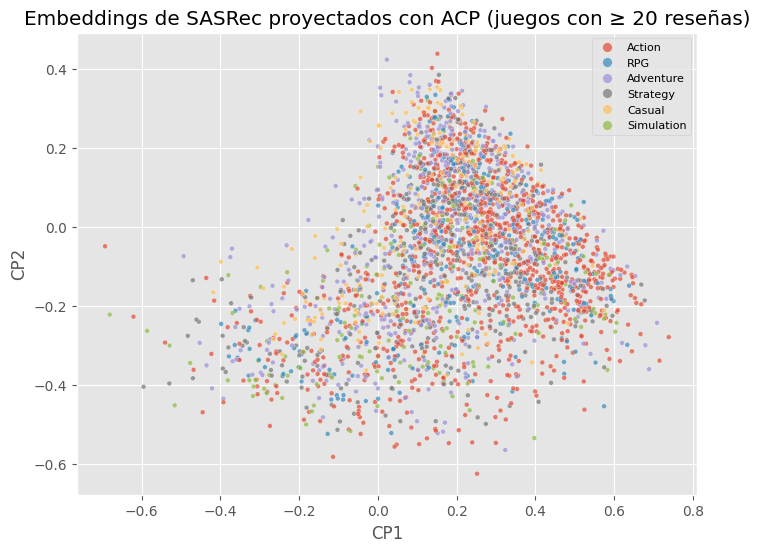

Coseno promedio mismo género: 0.028 | géneros distintos: -0.003


In [38]:
E = sasrec.items.weight.detach().cpu().numpy()[1:]           # sin el relleno
generos_items = np.asarray(genero.loc[1:N].values, dtype=object)
principales = pd.Series(generos_items).value_counts().head(6).index
visibles = np.isin(generos_items, principales) & (mapa_items["popularidad"].values >= 20)

coord = PCA(n_components=2, random_state=SEMILLA).fit_transform(E)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=coord[visibles, 0], y=coord[visibles, 1], hue=generos_items[visibles], s=12, alpha=0.7)
plt.title("Embeddings de SASRec proyectados con ACP (juegos con ≥ 20 reseñas)")
plt.xlabel("CP1"); plt.ylabel("CP2")
plt.legend(fontsize=8, markerscale=2)
plt.show()

# Similitud coseno promedio dentro del mismo género vs entre géneros distintos
En = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
idx = np.where(visibles)[0]
idx = np.random.default_rng(SEMILLA).choice(idx, size=min(2000, len(idx)), replace=False)
S = En[idx] @ En[idx].T
mismo = generos_items[idx][:, None] == generos_items[idx][None, :]
np.fill_diagonal(mismo, False)
fuera_diag = ~np.eye(len(idx), dtype=bool)
print(f"Coseno promedio mismo género: {S[mismo].mean():.3f} | géneros distintos: {S[~mismo & fuera_diag].mean():.3f}")

### 8.7 Conclusión: ¿vale la pena el Transformer en videojuegos?

**Sí.** Resultados en prueba (reportados una sola vez):

| Modelo | HR@10 | NDCG@10 | MRR@20 | Cobertura@10 |
|---|---|---|---|---|
| Popularidad | 0,0552 | 0,0282 | 0,0218 | 0,9 % |
| Reglas de asociación | 0,0572 | 0,0288 | 0,0222 | 0,9 % |
| Ítem–ítem coseno (γ = 0,9) | 0,0861 | 0,0452 | 0,0361 | 75,6 % |
| **SASRec (config C)** | **0,1110** | **0,0580** | **0,0461** | 56,5 % |

- **Precisión:** SASRec acierta el próximo juego dentro del Top-10 en el **11,1 %** de los usuarios, un **29 % más** que la mejor línea base (ítem–ítem coseno), y mejora en la misma proporción NDCG y MRR: no solo acierta más, sino que pone el juego correcto más arriba. Gana en todas las métricas y valores de K.
- **Las reglas casi no aportan.** Con solo 252 reglas sobre los 300 juegos más populares, apenas superan a la popularidad: en una base tan dispersa casi ningún par de juegos alcanza soporte suficiente.
- **Cobertura:** SASRec recomienda el 56,5 % del catálogo, frente al 0,9 % de popularidad. El coseno cubre más (75,6 %) pero acierta menos: SASRec cambia algo de diversidad por precisión, y ese sesgo hacia lo popular es algo que el analista de la Entrega 2 debe advertir.
- **Segmentos:** la ventaja es mayor en **historiales largos** (HR@10 0,105 vs 0,076 del coseno, +37 %) que en cortos (0,116 vs 0,093, +24 %), coherente con que la atención aprovecha la secuencia. En **juegos de cola larga** todos los modelos fallan (SASRec 0,018 vs coseno 0,017): predecir un juego poco conocido sigue siendo el problema abierto.
- **Selección por validación:** las tres configuraciones quedaron cerca (NDCG@10 de validación 0,058, 0,059 y 0,061); la C, con vectores de 128 y más dropout, fue la mejor y paró en la época 18 de 23.
- **Costo:** entrenar la configuración elegida tomó **288 s en GPU T4** (772 s las tres), contra 1,5 s del coseno; pero la inferencia es igual de barata (0,09 ms por usuario contra 0,07 ms) y el modelo pesa 4,3 MB, así que corre sin problema en CPU dentro del dashboard.

**Veredicto:** en videojuegos el orden del historial tiene señal (hallazgo 4) y SASRec la aprovecha. El costo extra es solo de entrenamiento, una vez y en minutos, y a cambio se obtiene casi un 30 % más de aciertos. Vale la pena.

**Comparación con el artículo original:** Kang y McAuley reportan HR@10 ≈ 0,87 en Steam, pero comparando el juego correcto contra solo 100 juegos al azar. Nosotros rankeamos el catálogo completo (6.738 juegos), una prueba mucho más exigente, así que los números no son comparables.

**Limitaciones:** la fecha viene por día (los empates se ordenan por el archivo), la reseña es una señal de compra imperfecta (no todos los que compran reseñan), trabajamos con una muestra de 40.000 usuarios y predecir el siguiente juego no explica **por qué** la persona lo eligió.

**Plan para la Entrega 2:** dashboard en Streamlit que carga `sasrec.pt` en CPU, simulador de historial con el Top-N de SASRec y de las líneas base, pesos de atención y un analista con LLM que explica (sin agregar ni reordenar) la lista y advierte el sesgo de popularidad.

## 9. Exportación para el repositorio

Archivos que pide el certamen (sin nombres de usuario, solo números):

| Archivo | Contenido |
|---|---|
| `data/secuencias.parquet` | Una fila por usuario: número de usuario y su secuencia ordenada de juegos (índices del modelo). |
| `data/mapa_items.csv` | Índice del modelo → id de Steam, nombre, géneros, género principal, precio y popularidad. |
| `data/metricas.csv` | Tabla final de prueba de los cuatro modelos. |
| `modelos/sasrec.pt` | Pesos de SASRec y su configuración, para cargarlo en el dashboard. |

In [39]:
os.makedirs("data", exist_ok=True)
os.makedirs("modelos", exist_ok=True)

secuencias = pd.DataFrame({"usuario": usuarios, "secuencia": [list(map(int, h)) for h in historial.values]})
secuencias["largo"] = secuencias["secuencia"].str.len()
secuencias.to_parquet("data/secuencias.parquet", index=False)

mapa_exportar = mapa_items.copy()
mapa_exportar["generos"] = mapa_exportar["generos"].apply(lambda g: "|".join(g))
mapa_exportar.reset_index().to_csv("data/mapa_items.csv", index=False)

tabla_final.rename_axis("modelo").reset_index().to_csv("data/metricas.csv", index=False)

torch.save({"config": CONFIGS[MEJOR], "n_items": int(N), "largo": LARGO, "semilla": SEMILLA,
            "estado": {k: v.cpu() for k, v in sasrec.state_dict().items()}}, "modelos/sasrec.pt")

for ruta in ["data/secuencias.parquet", "data/mapa_items.csv", "data/metricas.csv", "modelos/sasrec.pt"]:
    print(f"{ruta:28s} {os.path.getsize(ruta)/1e6:8.2f} MB")

# Copia en Drive para descargarlos y subirlos a GitHub
for carpeta in ["data", "modelos"]:
    shutil.copytree(carpeta, os.path.join(CARPETA_DRIVE, "repositorio", carpeta), dirs_exist_ok=True)
print(f"\nCopiados a {CARPETA_DRIVE}/repositorio")

data/secuencias.parquet          1.14 MB
data/mapa_items.csv              0.54 MB
data/metricas.csv                0.00 MB
modelos/sasrec.pt                4.28 MB

Copiados a /content/drive/MyDrive/Certamen2_Steam/repositorio


In [40]:
# Comprobación: el modelo guardado se carga en CPU y recomienda igual (así lo usará el dashboard)
guardado = torch.load("modelos/sasrec.pt", map_location="cpu")
modelo_cpu = SASRec(guardado["n_items"], guardado["largo"], **guardado["config"])
modelo_cpu.load_state_dict(guardado["estado"])
modelo_cpu.eval()

h = entrena_mas_valida.values[0]
with torch.no_grad():
    a = modelo_cpu.puntajes(torch.tensor([rellenar(h)]))[0]
    b = puntajes_sasrec([h])[0].cpu()
print("Mismas recomendaciones en CPU:", torch.equal(a.topk(10).indices, b.topk(10).indices))

Mismas recomendaciones en CPU: True
